<a href="https://colab.research.google.com/github/ArifahZhafirah/PEMBELAJARAN-MESIN/blob/main/JS10/LAB-04/PEMMES4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Lab 4
Klasifikasi Siang dan Malang dengan ANN

#Pengantar
Pada lab ini, mahasiswa akan mempelajari cara membangun model klasifikasi citra siang dan malam menggunakan Artificial Neural Network (ANN). Model akan dilatih menggunakan fitur HOG (Histogram of Oriented Gradients) yang diekstraksi dari citra. Mahasiswa akan menjalani alur lengkap mulai dari membaca data, pra pengolahan citra, ekstraksi fitur, normalisasi, membangun model, hingga evaluasi.

#Dataset
Gunakan dataset citra siang dan malam pada lab Lab 5

In [9]:
from google.colab import drive
drive.mount('/content/drive')
%cd "/content/drive/MyDrive/Semester5/Pembelajaran Mesin/TG10_244107020188_Arifah Zhafirah Wikananda"
!ls images/training

Mounted at /content/drive
/content/drive/MyDrive/Semester5/Pembelajaran Mesin/TG10_244107020188_Arifah Zhafirah Wikananda
day  night


#Langkah 1 - Import Library
Import library yang dibutuhkan

In [10]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import cv2

from skimage.feature import hog
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models

#Langkah 2 - Load Dataset
Gunakan fungsi berikut dan load dataset. Pastikan direktori dataset telah sesuai.

In [11]:
# Load images and labels from a directory structure
def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []
    for folder in p.glob('*'):
        label = folder.name
        for file in folder.glob('*.jpg'):
            img = cv2.imread(str(file))
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img_list.append((img, label))
    return img_list

train_dir = "images/training/"
test_dir  = "images/test/"

train_img = load_dataset(train_dir)
test_img  = load_dataset(test_dir)

#Langkah 2 - Pra Pengolahan
Risize dan lakukan pelabelan data

In [12]:
# Preprocess images: resize and encode labels
def resize_image(img, size=(256,256)):
    return cv2.resize(img, size)

def label_encoder(label):
    return 1 if label == 'day' else 0

def preprocess(img_list):
    X = []
    y = []
    for img, label in img_list:
        img_std = resize_image(img)
        X.append(img_std)
        y.append(label_encoder(label))
    return X, y

X_train_img, y_train = preprocess(train_img)
X_test_img,  y_test  = preprocess(test_img)

#Langkah 3 - Ekstraksi Fitur
Selanjut, lakukan proses ekstraksi fitur. Fitur yang akan digunakan adalah HoG. Pelajari HoG lebih lanjut pada https://scikit-image.org/docs/0.25.x/auto_examples/features_detection/plot_hog.html

In [13]:
# Extract HOG features
def extract_hog(X_imgs):
    feats = []
    for img in X_imgs:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        hog_feat = hog(gray,
                       orientations=9,
                       pixels_per_cell=(8,8),
                       cells_per_block=(2,2),
                       block_norm='L2-Hys',
                       visualize=False,
                       feature_vector=True)
        feats.append(hog_feat)
    return np.array(feats)

X_train_feat = extract_hog(X_train_img)
X_test_feat  = extract_hog(X_test_img)

#Langkah 4 - Standardisasi Fitur

In [14]:
# Normalize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_feat)
X_test_scaled  = scaler.transform(X_test_feat)

#Langkah 5 - Buat Data Latih dan Validasi

In [15]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_scaled, y_train,
    test_size=0.2,
    random_state=42
)

# Convert label ke numpy array
y_train = np.array(y_train)
y_val   = np.array(y_val)
y_test  = np.array(y_test)

#Langkah 6 - Buat Model ANN
Arsitektur model yang digunakan adalah,
*   Input Layer
*   Hidden Layer 1 - 128 Nodes - ReLU
*   Hidden Layer 2 - 64 Nodes - ReLu
*   Output Layer - 2 Nodes - Sigmoid



In [16]:
input_dim = X_train.shape[1]

model = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │     4,428,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,436,737 (16.92 MB)

 Trainable params: 4,436,737 (16.92 MB)

 Non-trainable params: 0 (0.00 B)

Anda akan mendapatkan summary dari arsitektur model. Informasi ini penting untuk mengetahui bentuk dari arsitektur ANN dan jumlah parameter yang dilatih.

#Langkah 7 - Latih Model

In [17]:
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val)
)

Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 328ms/step - accuracy: 0.7604 - loss: 0.7774 - val_accuracy: 0.9583 - val_loss: 0.5392
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 160ms/step - accuracy: 0.9740 - loss: 0.1302 - val_accuracy: 0.9792 - val_loss: 0.7454
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 169ms/step - accuracy: 1.0000 - loss: 3.7950e-04 - val_accuracy: 0.9792 - val_loss: 0.7806
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 159ms/step - accuracy: 1.0000 - loss: 6.1251e-05 - val_accuracy: 0.9792 - val_loss: 0.8127
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 139ms/step - accuracy: 1.0000 - loss: 8.2643e-05 - val_accuracy: 0.9792 - val_loss: 0.8308
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 115ms/step - accuracy: 1.0000 - loss: 3.3142e-05 - val_accuracy: 0.9792 - val_loss: 0.8417
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 87ms/step - accuracy: 1.0000 - loss: 1.2987e-05 - val_accuracy: 0.9792 - val_loss: 0.8479
Epoch 8/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 96ms/step - accuracy: 1.0000 - loss: 6.9534e-06 - val_accura

Anda dapat mengakses ulang performansi model dengan menggunakan variabel history yang telah dibuat.

#Langkah 8 - Evaluasi Model dengan Data Test

In [18]:
test_loss, test_acc = model.evaluate(X_test_scaled, y_test)
print("Akurasi Test:", test_acc)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.8562 - loss: 2.4282
Akurasi Test: 0.856249988079071


#Langkah 9 - Buat Laporan Performansi Model

In [19]:
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype(int)

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
              precision    recall  f1-score   support

           0       0.83      0.90      0.86        80
           1       0.89      0.81      0.85        80

    accuracy                           0.86       160
   macro avg       0.86      0.86      0.86       160
weighted avg       0.86      0.86      0.86       160

[[72  8]
 [15 65]]


#Langkah 10 - Visualisasi Proses Training
Visualisasi ini penting untuk proses monitoring performa model. Visualisasi menggunakan konsep Receiver Operating Characteristic (ROC) untuk mengetahui performa model tiap epoch.

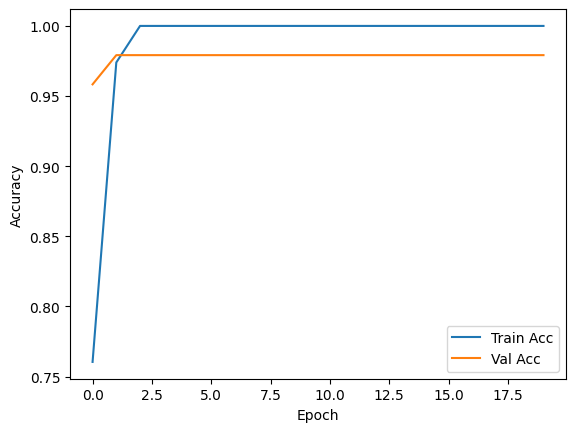

In [20]:
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

Dari grafik tersebut, apa yang bisa Anda interpretasikan?

Interpretasi Grafik

Dari grafik terlihat model belajar sangat cepat. Akurasi data latih (Train Acc) naik dari sekitar 0,80 pada epoch pertama menjadi sekitar 0,98 pada epoch kedua, lalu mencapai 1,00 sejak epoch ke-4 dan tetap datar sampai epoch ke-20. Akurasi validasi (Val Acc) sudah tinggi sejak awal, sempat turun sedikit ke sekitar 0,96 pada epoch ke-3, kemudian stabil di sekitar 0,98. Karena kedua kurva sudah mendatar setelah epoch ke-4, melatih sampai 20 epoch tidak memberi perbaikan lagi.

Jarak antara akurasi latih (1,00) dan validasi (sekitar 0,98) kecil, jadi model mampu mengenali pola siang dan malam dari fitur HOG dengan baik pada data yang belum dilihat. Namun jarak kecil itu tetap menandakan sedikit overfitting, yaitu model menghafal data latih dengan sempurna sementara performa pada data baru sedikit lebih rendah. Hal ini wajar karena fiturnya sangat banyak (34.596 fitur HOG per citra) dibanding datanya yang hanya 192 citra latih. Pada data test, akurasinya sekitar 0,95. Angka ini bisa sedikit berbeda setiap kali kode dijalankan karena bobot awal jaringan diacak.

Jika ingin diperbaiki, model dapat diberi Dropout atau early stopping, jumlah fitur dikurangi, atau data latih diperbanyak dengan augmentasi.



#Langkah 11 - Simpan Model
Simpan model untuk kebutuhan produksi.

In [21]:
model.save('day_night_classifier_model.h5')